In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import eda_utils as eda

# Load the precomputed_values.pkl file
precomputed_values_path = 'data/backtest/precomputed_values.pkl'
precomputed_values = pd.read_pickle(precomputed_values_path)
print(precomputed_values[0].keys())
len(precomputed_values)

dict_keys(['window_start', 'window_end', 'pair', 'hedge_ratio', 'spread', 'z_spread', 'split_index', 'high1', 'high2', 'low1', 'low2', 'vol1', 'vol2', 'close1', 'close2', 'corr_coef', 'half_life'])


2357

In [30]:
# Extract relevant fields from precomputed_values and create a DataFrame
stop_loss_threshold = 1 

precomputed_values = eda.create_target_column(precomputed_values, stop_loss_threshold)
precomputed_values = eda.generate_features(precomputed_values)

print(precomputed_values[0].keys())

data = []
for item in precomputed_values:
    data.append({
        # 'window_start': item['window_start'],
        # 'window_end': item['window_end'],
        # 'pair': item['pair'],
        'hedge_ratio': item['hedge_ratio'],
        'split_index': item['split_index'],
        'position': item['position'],
        'trade': item['trade'],
        'close1_rsi_split': item['close1_rsi_split'],
        'close2_rsi_split': item['close2_rsi_split'],
        'close1_ma_50_pct_diff': item['close1_ma_50_pct_diff'],
        'close2_ma_50_pct_diff': item['close2_ma_50_pct_diff'],
        'close1_ma_200_pct_diff': item['close1_ma_200_pct_diff'],
        'close2_ma_200_pct_diff': item['close2_ma_200_pct_diff'],
        'close1_vwap_100_pct_diff': item['close1_vwap_100_pct_diff'],
        'close2_vwap_100_pct_diff': item['close2_vwap_100_pct_diff'],
        'z_spread_split': item['z_spread_split'],
        'var_spread': item['var_spread'],
        'corr_coef': item['corr_coef'],
        'half_life': item['half_life'],
        'z_slope_pre_split': item['z_slope_pre_split'],
        'z_volatility': item['z_volatility'],
        'z_spread_deviation': item['z_spread_deviation'],
        'z_spread': item['z_spread'],
    })

# Convert to DataFrame
df = pd.DataFrame(data)
df['z_spread_positioned'] = df['z_spread_split'] * df['position']
df['z_slope_positioned'] = df['z_slope_pre_split'] * df['position']
df['rsi_diff'] = df['close1_rsi_split'] - df['close2_rsi_split']
df['vwap_diff'] = df['close1_vwap_100_pct_diff'] - df['close2_vwap_100_pct_diff']
df['ma_50_pct_diff'] = df['close1_ma_50_pct_diff'] - df['close2_ma_50_pct_diff']
df['ma_200_pct_diff'] = df['close1_ma_200_pct_diff'] - df['close2_ma_200_pct_diff']
df.head()

dict_keys(['window_start', 'window_end', 'pair', 'hedge_ratio', 'spread', 'z_spread', 'split_index', 'high1', 'high2', 'low1', 'low2', 'vol1', 'vol2', 'close1', 'close2', 'corr_coef', 'half_life', 'position', 'trade', 'rr_ratio', 'close1_ma_7', 'close2_ma_7', 'close1_ma_15', 'close2_ma_15', 'close1_ma_50', 'close2_ma_50', 'close1_ma_200', 'close2_ma_200', 'close1_rsi', 'close2_rsi', 'z_spread_split', 'var_spread', 'close1_ma_7_pct_diff', 'close2_ma_7_pct_diff', 'close1_ma_15_pct_diff', 'close2_ma_15_pct_diff', 'close1_ma_50_pct_diff', 'close2_ma_50_pct_diff', 'close1_ma_200_pct_diff', 'close2_ma_200_pct_diff', 'close1_rsi_split', 'close2_rsi_split', 'close1_vwap_100_pct_diff', 'close2_vwap_100_pct_diff', 'z_slope_pre_split', 'z_volatility', 'z_spread_deviation'])


,hedge_ratio,split_index,position,trade,close1_rsi_split,close2_rsi_split,close1_ma_50_pct_diff,close2_ma_50_pct_diff,close1_ma_200_pct_diff,close2_ma_200_pct_diff,...,z_slope_pre_split,z_volatility,z_spread_deviation,z_spread,z_spread_positioned,z_slope_positioned,rsi_diff,vwap_diff,ma_50_pct_diff,ma_200_pct_diff
0,0.898396,240,1.0,1,43.753736,51.851852,1.261542,3.443842,-1.716825,0.559653,...,-0.062368,0.711932,-0.737824,Open Time 2025-04-04 16:00:00 0.975576 2025...,-1.973065,-0.062368,-8.098116,-2.752918,-2.182300,-2.276478
1,0.950030,240,1.0,0,55.238095,52.043597,1.168102,2.232270,-3.145852,-0.733021,...,0.026547,0.230870,0.264422,Open Time 2025-04-04 16:00:00 0.519868 2025...,-1.706139,0.026547,3.194499,-1.997675,-1.064169,-2.412831
2,1.086526,240,-1.0,0,52.096774,41.457286,2.490788,0.197007,-2.358549,-5.215836,...,0.095865,0.792564,1.110634,Open Time 2025-04-04 16:00:00 -0.169905 2025...,-2.514582,-0.095865,10.639488,3.098313,2.293781,2.857287
3,0.993484,240,1.0,1,45.197740,52.564103,0.804739,2.732322,-3.947882,-1.573889,...,-0.059615,0.502227,-0.556187,Open Time 2025-04-04 16:00:00 -0.478893 2025...,-1.675162,-0.059615,-7.366362,-2.599680,-1.927583,-2.373993
4,1.091998,240,1.0,1,46.409336,51.851852,1.138749,3.443842,-2.875874,0.559653,...,0.021270,0.521706,-0.459756,Open Time 2025-04-04 16:00:00 -0.330152 2025...,-2.426091,0.021270,-5.442516,-2.929012,-2.305093,-3.435527


In [31]:
filters = {
    'half_life1': df[df['half_life'] < 50],
    'half_life2': df[df['half_life'] < 20],
'close2_below_vwap3': df[df['close2_vwap_100_pct_diff'] < -3],

}
for name, subset in filters.items():
    N_total = len(df)
    N_after = len(subset)
    P_base = df['trade'].mean()
    P_after = subset['trade'].mean()
    lift = P_after / P_base
    retention = N_after / N_total
    print(f"{name}: Lift={lift:.2f}, Retention={retention:.2%}, P_after={P_after:.2%}")

# half_life_thresholds = list(range(20, 80, 5))  # test cutoffs from 20 to 75

# for threshold in half_life_thresholds:
#     subset = df[df['half_life'] < threshold]
#     if len(subset) == 0:
#         continue
#     p_after = subset['trade'].mean()
#     lift = p_after / df['trade'].mean()
#     retention = len(subset) / len(df)
#     efficiency = lift * retention
#     print(f"half_life < {threshold}: Lift={lift:.2f}, Retention={retention:.2%}, P_after={p_after:.2%}, Efficiency={efficiency:.3f}")

total_true = df[df['trade'] == 1].shape[0]

for threshold in range(10, 80, 5):
    subset = df[df['half_life'] < threshold]
    true_after = subset[subset['trade'] == 1].shape[0]
    true_retention = true_after / total_true
    p_after = subset['trade'].mean()
    lift = p_after / df['trade'].mean()
    retention = len(subset) / len(df)
    print(f"half_life < {threshold}: True Retention={true_retention:.2%}, Lift={lift:.2f}, Retention={retention:.2%}")


half_life1: Lift=1.01, Retention=98.77%, P_after=29.73%
half_life2: Lift=1.07, Retention=82.61%, P_after=31.48%
close2_below_vwap3: Lift=0.89, Retention=20.20%, P_after=26.26%
half_life < 10: True Retention=29.50%, Lift=1.07, Retention=27.58%
half_life < 15: True Retention=68.20%, Lift=1.07, Retention=63.68%
half_life < 20: True Retention=88.20%, Lift=1.07, Retention=82.61%
half_life < 25: True Retention=93.81%, Lift=1.04, Retention=90.54%
half_life < 30: True Retention=96.83%, Lift=1.03, Retention=94.40%
half_life < 35: True Retention=98.27%, Lift=1.02, Retention=96.31%
half_life < 40: True Retention=99.42%, Lift=1.02, Retention=97.50%
half_life < 45: True Retention=99.42%, Lift=1.01, Retention=98.43%
half_life < 50: True Retention=99.57%, Lift=1.01, Retention=98.77%
half_life < 55: True Retention=99.71%, Lift=1.00, Retention=99.24%
half_life < 60: True Retention=99.71%, Lift=1.00, Retention=99.41%
half_life < 65: True Retention=99.71%, Lift=1.00, Retention=99.41%
half_life < 70: True

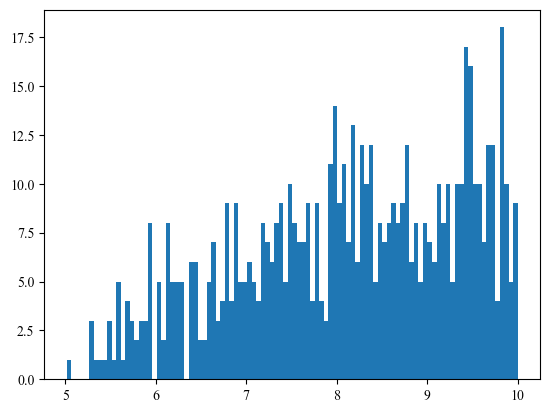

count    650.000000
mean       2.021103
std        0.499886
min        0.873619
25%        1.659285
50%        1.968465
75%        2.327651
max        4.094276
Name: z_spread_split, dtype: float64


,hedge_ratio,split_index,position,trade,close1_rsi_split,close2_rsi_split,close1_ma_50_pct_diff,close2_ma_50_pct_diff,close1_ma_200_pct_diff,close2_ma_200_pct_diff,...,z_slope_pre_split,z_volatility,z_spread_deviation,z_spread,z_spread_positioned,z_slope_positioned,rsi_diff,vwap_diff,ma_50_pct_diff,ma_200_pct_diff
13,1.201736,240,1.0,1,45.674487,52.564103,1.222581,2.732322,-4.567012,-1.573889,...,-0.119994,0.553280,-0.757973,Open Time 2025-04-04 16:00:00 -1.267102 2025...,-2.000772,-0.119994,-6.889616,-2.413550,-1.509741,-2.993123
15,0.828748,240,-1.0,1,47.692308,38.446215,1.589296,-0.594842,-4.135791,-8.442645,...,0.085493,0.748539,0.967624,Open Time 2025-04-04 16:00:00 1.146038 2025...,-2.232748,-0.085493,9.246093,3.965148,2.184139,4.306853
16,0.850512,240,-1.0,1,51.898734,45.481928,3.666521,1.489617,3.502751,-0.268794,...,0.193702,0.714155,0.963234,Open Time 2025-04-04 16:00:00 0.428298 2025...,-2.040636,-0.193702,6.416806,2.691013,2.176904,3.771545
17,0.838937,240,1.0,0,39.876881,51.109990,0.366746,2.427902,-2.814566,-0.509680,...,-0.014403,0.555746,-0.515029,Open Time 2025-04-04 16:00:00 0.970192 2025...,-1.520248,-0.014403,-11.233109,-2.263402,-2.061156,-2.304885
28,1.063973,240,1.0,0,37.419355,54.471545,-3.113623,-0.861174,-7.741466,-4.978848,...,-0.130400,1.052172,-1.563215,Open Time 2025-04-03 15:00:00 -0.100543 2025...,-2.726883,-0.130400,-17.052190,-3.297766,-2.252450,-2.762618
29,0.950682,240,-1.0,1,49.629630,36.190476,-0.477601,-2.845584,-3.760873,-6.819263,...,0.081391,0.710229,0.891496,Open Time 2025-04-03 15:00:00 -0.125335 2025...,-2.352145,-0.081391,13.439153,3.671188,2.367983,3.058390
36,1.122804,240,-1.0,1,58.139535,54.471545,1.417254,-0.861174,-3.280869,-4.978848,...,0.142986,0.464035,0.750563,Open Time 2025-04-03 15:00:00 0.542264 2025...,-1.773945,-0.142986,3.667990,2.157750,2.278428,1.697979
46,1.247351,240,-1.0,1,52.212389,34.085779,0.813436,-1.474079,-2.346259,-4.348085,...,0.091113,1.045830,1.156667,Open Time 2025-04-03 15:00:00 0.825759 2025...,-2.454838,-0.091113,18.126611,4.035606,2.287515,2.001826
47,0.959090,240,1.0,0,47.191011,50.322581,-1.933398,-0.441716,-8.956954,-6.252270,...,-0.087963,0.321003,-0.434144,Open Time 2025-04-03 15:00:00 -0.593673 2025...,-2.005352,-0.087963,-3.131569,-3.340341,-1.491682,-2.704684
75,1.189536,240,1.0,0,75.968586,80.080545,-2.263694,0.865565,-11.230597,-6.575037,...,-0.082159,1.443640,-1.912060,Open Time 2025-04-02 14:00:00 -0.993523 2025...,-2.978782,-0.082159,-4.111959,-2.506940,-3.129259,-4.655560


In [32]:
# plot the histogram of half_life

df = df[df.half_life < 10]
# drop all rows if abs(z_spread_split) under 1.5 and over 3
plt.hist(df.half_life, bins=100)
plt.show()
# Display the DataFrame
print(np.abs(df['z_spread_split']).describe())
df.head(10)


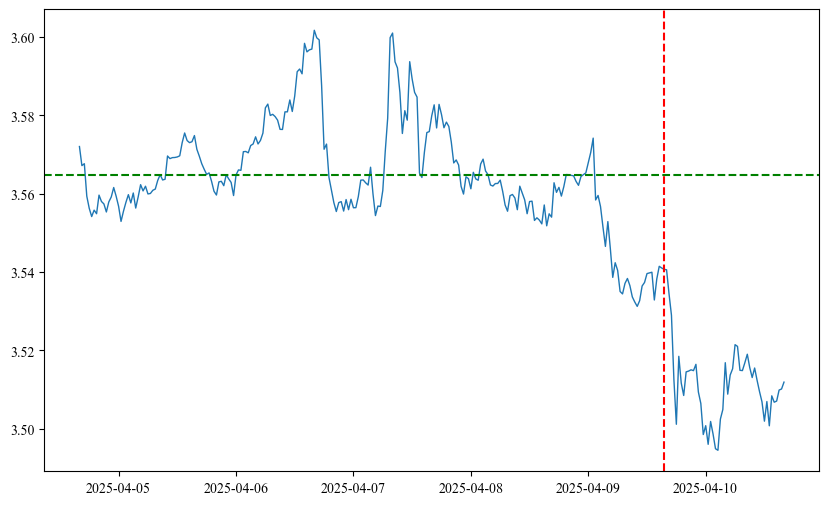

In [33]:
plt.figure(figsize=(10, 6))
# Customize plot
spread = precomputed_values[1]['spread']
split_index = precomputed_values[1]['split_index']

# Plot components
plt.plot(spread, label='Spread', linewidth=1)
plt.axvline(spread.index[split_index-1], color='r', linestyle='--', label='Split Index')
plt.axhline(np.mean(spread.iloc[:split_index]), color='g', linestyle='--', label='Mean (Training)')

In [34]:
# import torch
# import torch.nn as nn
# import torch.optim as optim
# from torch.utils.data import TensorDataset, DataLoader  #, WeightedRandomSampler
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# # Define features and target from your DataFrame
# features = [
#     'z_spread_positioned', 'z_slope_positioned',
#     'rsi_diff', 'vwap_diff', 'ma_50_pct_diff', 'ma_200_pct_diff',
#     'var_spread', 'corr_coef', 'half_life', 'z_spread_deviation'
# ]
# X = df[features].values
# y = df['trade'].values  # Binary: 0 (Not Trade) or 1 (Trade)

# # Split into train+val and test (80% train+val, 20% test)
# X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, shuffle=False)

# # Further split train+val into training and validation sets (e.g., 80% train, 20% val)
# X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, shuffle=False)

# ##############################################
# # Preprocessing: Standardize features using training data
# ##############################################
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled   = scaler.transform(X_val)
# X_test_scaled  = scaler.transform(X_test)

# # Convert numpy arrays to torch tensors
# X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
# y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
# X_val_tensor   = torch.tensor(X_val_scaled, dtype=torch.float32)
# y_val_tensor   = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
# X_test_tensor  = torch.tensor(X_test_scaled, dtype=torch.float32)
# y_test_tensor  = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)


# # Print number of samples in each set
# print("Training Set:", X_train_tensor.shape, y_train_tensor.shape)
# print("Validation Set:", X_val_tensor.shape, y_val_tensor.shape)
# print("Test Set:", X_test_tensor.shape, y_test_tensor.shape)


# ##############################################
# # Compute class weight for handling imbalance
# ##############################################
# # Calculate pos_weight as (# negatives / # positives) from training data
# num_positive = (y_train_tensor == 1).sum().item()
# num_negative = (y_train_tensor == 0).sum().item()
# pos_weight = torch.tensor([num_negative / num_positive], dtype=torch.float32)
# print("Positive weight:", pos_weight.item())

# # Optionally, you could use a WeightedRandomSampler for the training loader:
# # weights = [pos_weight.item() if label == 1 else 1.0 for label in y_train]
# # sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

# # Create DataLoaders
# train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
# val_dataset   = TensorDataset(X_val_tensor, y_val_tensor)
# test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

# train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)  # or use sampler=sampler
# val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
# test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

# ##############################################
# # Define a simple feed-forward neural network
# ##############################################
# class FeedForwardNN(nn.Module):
#     def __init__(self, input_dim, hidden_dim, output_dim):
#         super(FeedForwardNN, self).__init__()
#         self.fc1 = nn.Linear(input_dim, hidden_dim)
#         self.fc2 = nn.Linear(hidden_dim, hidden_dim)
#         self.fc3 = nn.Linear(hidden_dim, output_dim)
#         self.batchnorm1 = nn.BatchNorm1d(hidden_dim)
#         self.batchnorm2 = nn.BatchNorm1d(hidden_dim)
#         self.relu = nn.ReLU()
#         self.dropout = nn.Dropout(p=0.2)
        
#     def forward(self, x): 
#         x = self.relu(self.batchnorm1(self.fc1(x)))
#         x = self.dropout(x)

#         x = self.relu(self.batchnorm2(self.fc2(x)))
#         x = self.dropout(x)

#         x = self.fc3(x)
#         return x

# input_dim = X_train_tensor.shape[1]
# model = FeedForwardNN(input_dim=input_dim, hidden_dim=64, output_dim=1)

# # Use GPU if available
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model.to(device)

# # Define loss function with class weight and optimizer
# criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
# optimizer = optim.Adam(model.parameters(), lr=0.0001)

# ##############################################
# # Training loop with validation monitoring
# ##############################################
# num_epochs = 500
# best_val_loss = float('inf')
# best_model_state = None

# for epoch in range(num_epochs):
#     model.train()
#     epoch_train_loss = 0.0
#     for batch_X, batch_y in train_loader:
#         batch_X, batch_y = batch_X.to(device), batch_y.to(device)
#         optimizer.zero_grad()
#         outputs = model(batch_X)
#         loss = criterion(outputs, batch_y)
#         loss.backward()
#         optimizer.step()
#         epoch_train_loss += loss.item()
    
#     avg_train_loss = epoch_train_loss / len(train_loader)
    
#     # Evaluate on the validation set
#     model.eval()
#     epoch_val_loss = 0.0
#     with torch.no_grad():
#         for batch_X, batch_y in val_loader:
#             batch_X, batch_y = batch_X.to(device), batch_y.to(device)
#             outputs = model(batch_X)
#             loss = criterion(outputs, batch_y)
#             epoch_val_loss += loss.item()
#     avg_val_loss = epoch_val_loss / len(val_loader)
    
#     if (epoch + 1) % 5 == 0 or epoch == 0:
#         print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")
    
#     # Save model if validation loss has improved
#     if avg_val_loss < best_val_loss:
#         best_val_loss = avg_val_loss
#         best_model_state = model.state_dict()


# # Load the best model state
# model.load_state_dict(best_model_state)
# print(f"\nBest Validation Loss: {best_val_loss:.4f}")


Train samples: 416, Validation samples: 104, Test samples: 130
Positive class weight: 1.89
Using device: cpu
Model Architecture:
SimpleMLP(
  (fc_other1): Linear(in_features=10, out_features=128, bias=True)
  (bn_other1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU()
  (dropout1): Dropout(p=0.4, inplace=False)
  (fc_other2): Linear(in_features=128, out_features=64, bias=True)
  (bn_other2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc_output): Linear(in_features=64, out_features=1, bias=True)
)

--- Starting Training ---
Epoch [1/500] - Train Loss: 0.9497, Val Loss: 0.8540
Epoch [5/500] - Train Loss: 0.9297, Val Loss: 0.8568
Epoch [10/500] - Train Loss: 0.9137, Val Loss: 0.8572
Epoch [15/500] - Train Loss: 0.9267, Val Loss: 0.8593
Epoch [20/500] - Train Loss: 0.9050, Val Loss: 0.8628
Epoch [25/500] - Train Loss: 0.8829, Val Loss: 0.8656
Early stopping

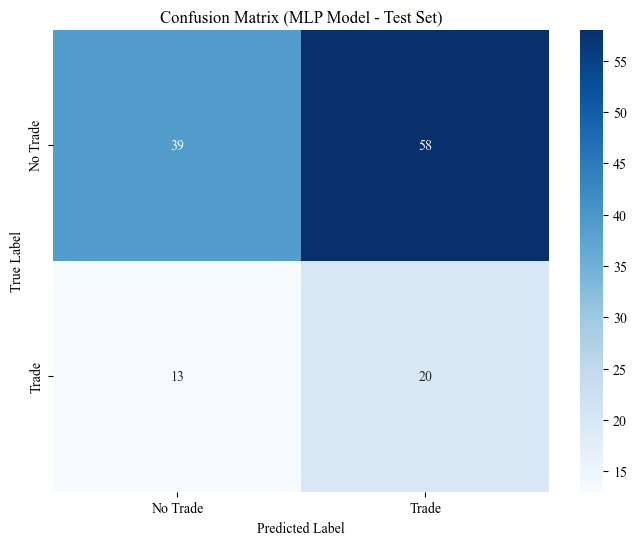

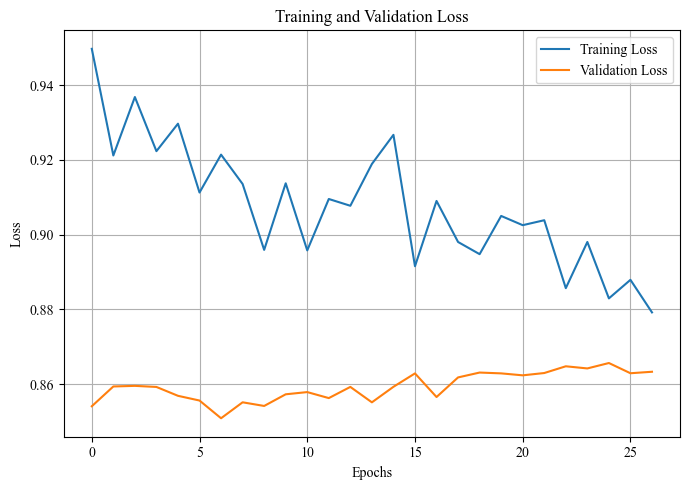

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
# Removed: from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import pandas as pd
import time


other_features = [
    'z_spread_positioned',
    'rsi_diff', 'vwap_diff', 'ma_50_pct_diff', 'ma_200_pct_diff',
    'var_spread', 'corr_coef', 'z_spread_deviation', 'z_slope_positioned', 'half_life',
]
all_features = other_features
X = df[all_features]
y = df['trade'].values

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, shuffle=False
)
print(f"Train samples: {len(X_train)}, Validation samples: {len(X_val)}, Test samples: {len(X_test)}")

scaler_other = StandardScaler()
X_train_other = torch.tensor(scaler_other.fit_transform(X_train), dtype=torch.float32)
X_val_other = torch.tensor(scaler_other.transform(X_val), dtype=torch.float32)
X_test_other = torch.tensor(scaler_other.transform(X_test), dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

num_positive = (y_train_tensor == 1).sum().item()
num_negative = (y_train_tensor == 0).sum().item()
if num_positive > 0 and num_negative > 0:
    pos_weight_val = num_negative / num_positive
    print(f"Positive class weight: {pos_weight_val:.2f}")
else:
    pos_weight_val = 1.0
pos_weight = torch.tensor([pos_weight_val], dtype=torch.float32)

batch_size = 32
train_loader = DataLoader(TensorDataset(X_train_other, y_train_tensor), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_other, y_val_tensor), batch_size=batch_size * 2, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_other, y_test_tensor), batch_size=batch_size * 2, shuffle=False)

class SimpleMLP(nn.Module):
    def __init__(self, num_other_features, hidden_dim, output_dim, dropout_rate=0.4):
        super(SimpleMLP, self).__init__()
        self.fc_other1 = nn.Linear(num_other_features, hidden_dim)
        self.bn_other1 = nn.BatchNorm1d(hidden_dim)
        self.relu = nn.ReLU()
        self.dropout1 = nn.Dropout(p=dropout_rate)

        self.fc_other2 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.bn_other2 = nn.BatchNorm1d(hidden_dim // 2)
        self.dropout2 = nn.Dropout(p=dropout_rate / 2)

        self.fc_output = nn.Linear(hidden_dim // 2, output_dim)

    def forward(self, other_input):
        x = self.fc_other1(other_input)
        x = self.bn_other1(x)
        x = self.relu(x)
        x = self.dropout1(x)

        x = self.fc_other2(x)
        x = self.bn_other2(x)
        x = self.relu(x)
        x = self.dropout2(x)

        output = self.fc_output(x)
        return output

hidden_dim_other = 128
output_dim = 1
num_other_features = X_train_other.shape[1]
dropout_p = 0.4
learning_rate = 0.0001 # This LR will now be constant
weight_decay = 1e-5
num_epochs = 500
early_stopping_patience = 20

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SimpleMLP(num_other_features, hidden_dim_other, output_dim, dropout_rate=dropout_p).to(device)
print(f"Using device: {device}")
print("Model Architecture:")
print(model)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
# Removed: scheduler = ReduceLROnPlateau(...)

best_val_loss = float('inf')
best_model_state = None
epochs_no_improve = 0
train_losses = []
val_losses = []
# Removed: learning_rates = []

print("\n--- Starting Training ---")
start_time = time.time()

for epoch in range(num_epochs):
    model.train()
    epoch_train_loss = 0.0
    for batch_other, batch_y in train_loader:
        batch_other, batch_y = batch_other.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = model(batch_other)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item()
    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for batch_other, batch_y in val_loader:
            batch_other, batch_y = batch_other.to(device), batch_y.to(device)
            outputs = model(batch_other)
            loss = criterion(outputs, batch_y)
            epoch_val_loss += loss.item()
    avg_val_loss = epoch_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # Removed: current_lr = optimizer.param_groups[0]['lr']
    # Removed: learning_rates.append(current_lr)
    # Removed: scheduler.step(avg_val_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        # Removed LR from print statement
        print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_state = model.state_dict()
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= early_stopping_patience:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

training_time = time.time() - start_time
print("\n--- Training Finished ---")
print(f"Total Training Time: {training_time:.2f} seconds")

if best_model_state:
    model.load_state_dict(best_model_state)
    print(f"Loaded best model state. Best Validation Loss: {best_val_loss:.4f}")
else:
    print("\nWarning: No best model state saved.")

model.eval()
all_preds = []
all_labels = []
all_probs = []

print("\n--- Starting Evaluation on Test Set ---")
eval_start_time = time.time()
with torch.no_grad():
    for batch_other, batch_y in test_loader:
        batch_other, batch_y = batch_other.to(device), batch_y.to(device)
        outputs = model(batch_other)
        probs = torch.sigmoid(outputs)
        predictions = (probs > 0.5).int()
        all_probs.extend(probs.cpu().numpy().flatten())
        all_preds.extend(predictions.cpu().numpy().flatten())
        all_labels.extend(batch_y.cpu().numpy().flatten())

eval_time = time.time() - eval_start_time
print(f"Evaluation Time: {eval_time:.2f} seconds")

print("\nTest Set Evaluation Results:")
accuracy = accuracy_score(all_labels, all_preds)
report = classification_report(all_labels, all_preds, target_names=['No Trade', 'Trade'], zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print("Classification Report:\n", report)

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Trade', 'Trade'], yticklabels=['No Trade', 'Trade'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (MLP Model - Test Set)')
plt.show()

# Plot only Training and Validation Loss
plt.figure(figsize=(7, 5)) # Adjusted figure size
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Test Accuracy: 0.45384615384615384
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.40      0.52        97
           1       0.26      0.61      0.36        33

    accuracy                           0.45       130
   macro avg       0.50      0.50      0.44       130
weighted avg       0.62      0.45      0.48       130



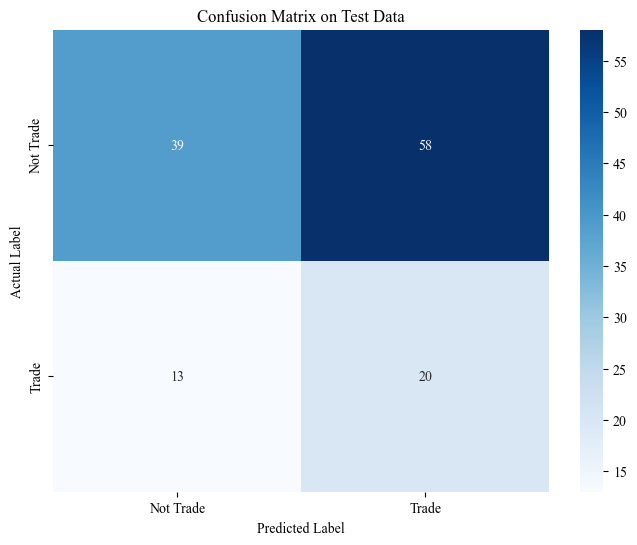

In [36]:

##############################################
# Evaluate on the Test Set using the best model
##############################################

model.eval()

all_preds = []
all_true = []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        outputs = model(batch_X)
        # Apply sigmoid and threshold at 0.5 to obtain binary predictions
        preds = (torch.sigmoid(outputs) >= 0.5).int()
        all_preds.extend(preds.cpu().numpy().squeeze())
        all_true.extend(batch_y.cpu().numpy().squeeze())

# Convert to integer type for metric calculations
all_preds = np.array(all_preds).astype(int)
all_true = np.array(all_true).astype(int)

test_acc = accuracy_score(all_true, all_preds)
print("Test Accuracy:", test_acc)
print("Classification Report:\n", classification_report(all_true, all_preds))

# Plot the confusion matrix
cm = confusion_matrix(all_true, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Trade', 'Trade'],
            yticklabels=['Not Trade', 'Trade'])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix on Test Data")
plt.show()
